## Pizza Sales Data Analysis

In [1]:
import pandas as pd 
import seaborn as sns 
import matplotlib.pyplot as plt 
import numpy as np 
import warnings 
warnings.filterwarnings("ignore")

In [2]:
df=pd.read_csv(r"C:\Users\bipin\Downloads\pizza_sales excel file.xlsx - pizza_sales.csv")

In [3]:
df.head()

,pizza_id,order_id,pizza_name_id,quantity,order_date,order_time,unit_price,total_price,pizza_size,pizza_category,pizza_ingredients,pizza_name
0,1,1,hawaiian_m,1,1/1/2015,11:38:36,13.25,13.25,M,Classic,"Sliced Ham, Pineapple, Mozzarella Cheese",The Hawaiian Pizza
1,2,2,classic_dlx_m,1,1/1/2015,11:57:40,16.00,16.00,M,Classic,"Pepperoni, Mushrooms, Red Onions, Red Peppers,...",The Classic Deluxe Pizza
2,3,2,five_cheese_l,1,1/1/2015,11:57:40,18.50,18.50,L,Veggie,"Mozzarella Cheese, Provolone Cheese, Smoked Go...",The Five Cheese Pizza
3,4,2,ital_supr_l,1,1/1/2015,11:57:40,20.75,20.75,L,Supreme,"Calabrese Salami, Capocollo, Tomatoes, Red Oni...",The Italian Supreme Pizza
4,5,2,mexicana_m,1,1/1/2015,11:57:40,16.00,16.00,M,Veggie,"Tomatoes, Red Peppers, Jalapeno Peppers, Red O...",The Mexicana Pizza


In [4]:
df.shape

(48620, 12)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48620 entries, 0 to 48619
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   pizza_id           48620 non-null  int64  
 1   order_id           48620 non-null  int64  
 2   pizza_name_id      48620 non-null  object 
 3   quantity           48620 non-null  int64  
 4   order_date         48620 non-null  object 
 5   order_time         48620 non-null  object 
 6   unit_price         48620 non-null  float64
 7   total_price        48620 non-null  float64
 8   pizza_size         48620 non-null  object 
 9   pizza_category     48620 non-null  object 
 10  pizza_ingredients  48620 non-null  object 
 11  pizza_name         48620 non-null  object 
dtypes: float64(2), int64(3), object(7)
memory usage: 4.5+ MB


In [6]:
df.isnull().sum()

pizza_id             0
order_id             0
pizza_name_id        0
quantity             0
order_date           0
order_time           0
unit_price           0
total_price          0
pizza_size           0
pizza_category       0
pizza_ingredients    0
pizza_name           0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
pizza_id,48620.0,24310.500000,14035.529381,1.00,12155.75,24310.5,36465.25,48620.00
order_id,48620.0,10701.479761,6180.119770,1.00,5337.00,10682.5,16100.00,21350.00
quantity,48620.0,1.019622,0.143077,1.00,1.00,1.0,1.00,4.00
unit_price,48620.0,16.494132,3.621789,9.75,12.75,16.5,20.25,35.95
total_price,48620.0,16.821474,4.437398,9.75,12.75,16.5,20.50,83.00


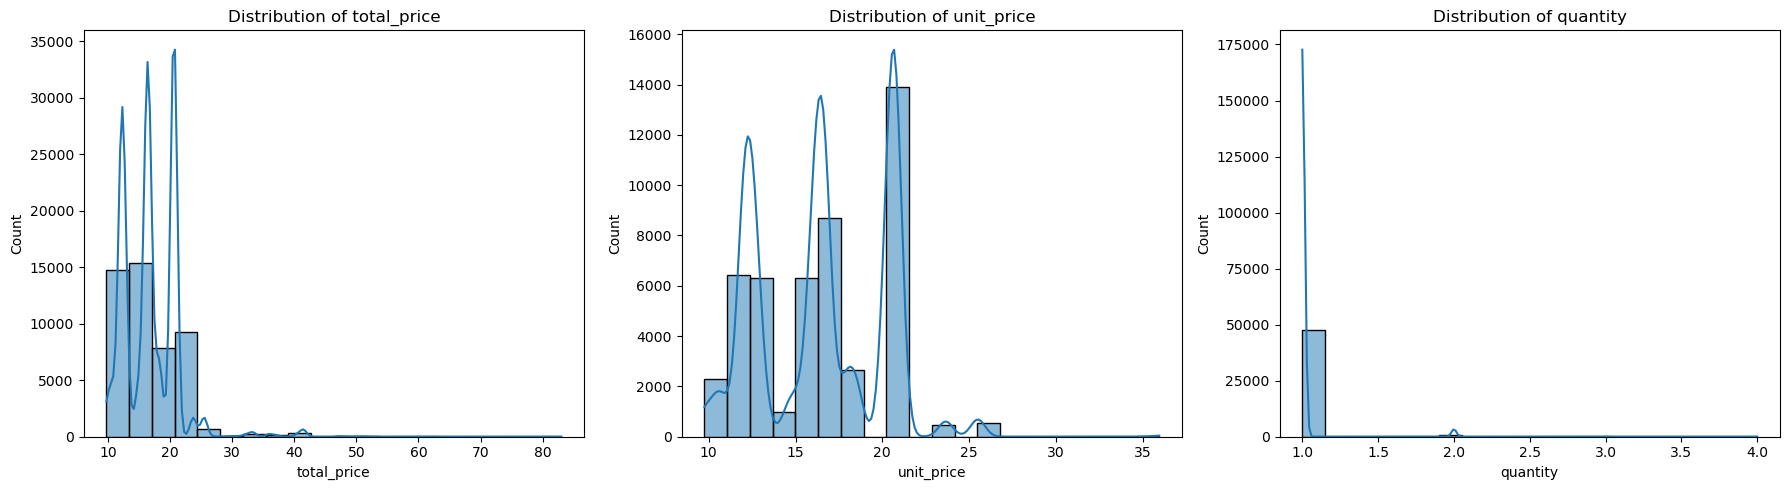

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, col in zip(axes, ["total_price", "unit_price", "quantity"]):
    sns.histplot(df[col], bins=20, kde=True, ax=ax)
    ax.set_title(f"Distribution of {col}")

plt.tight_layout()
plt.show()

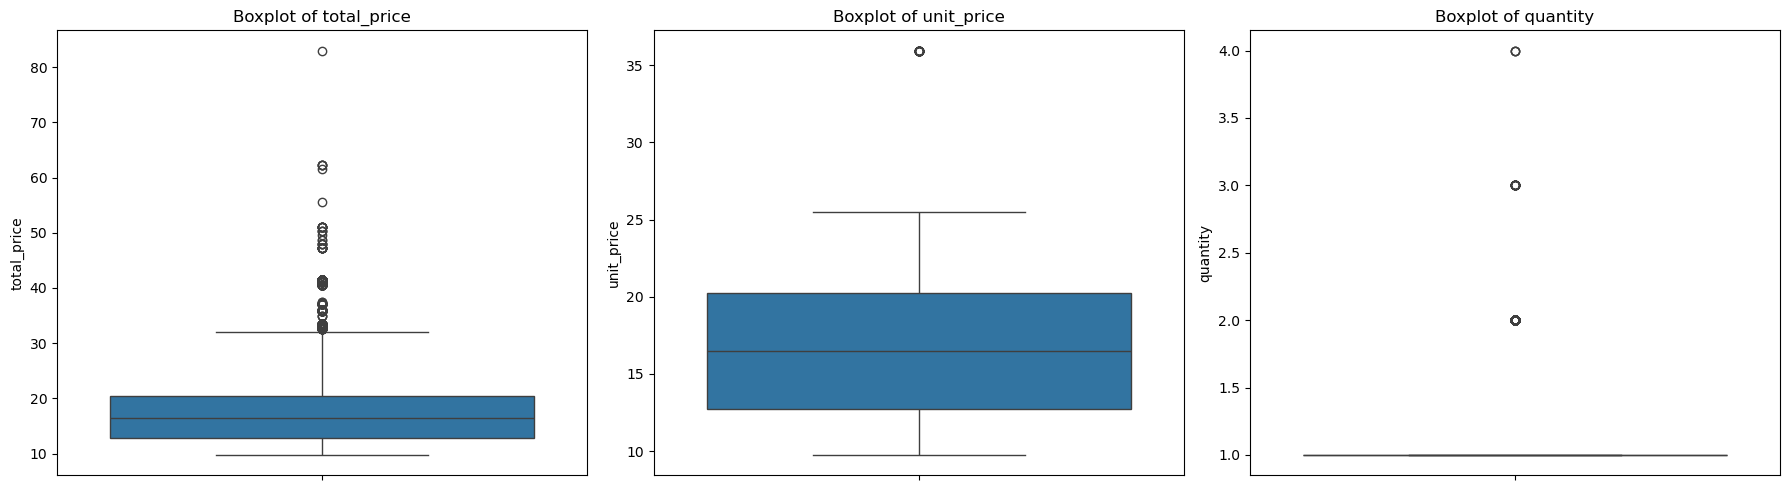

In [10]:
# Checking Outliers 

cols = ["total_price", "unit_price", "quantity"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, col in zip(axes, cols):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(f"Boxplot of {col}")

plt.tight_layout()
plt.show()

In [11]:
def find_outliers_iqr(data, col):
    Q1 = data[col].quantile(0.25)
    Q3 = data[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outliers = data[(data[col] < lower) | (data[col] > upper)]
    return outliers, lower, upper

for col in cols:
    outliers, lower, upper = find_outliers_iqr(df, col)
    print(f"{col}: {len(outliers)} outliers "
          f"(lower bound = {lower:.2f}, upper bound = {upper:.2f})")

total_price: 613 outliers (lower bound = 1.12, upper bound = 32.12)
unit_price: 28 outliers (lower bound = 1.50, upper bound = 31.50)
quantity: 927 outliers (lower bound = 1.00, upper bound = 1.00)


####  Data Cleaning And Feature Engineering


In [12]:
df["order_date"]=pd.to_datetime(df["order_date"])
print(df["order_date"].dtypes)

datetime64[ns]


In [13]:
df["Month"]=pd.to_datetime(df["order_date"]).dt.month_name()
df["Weekday"]=pd.to_datetime(df["order_date"]).dt.day_name()
df.head()

,pizza_id,order_id,pizza_name_id,quantity,order_date,order_time,unit_price,total_price,pizza_size,pizza_category,pizza_ingredients,pizza_name,Month,Weekday
0,1,1,hawaiian_m,1,2015-01-01,11:38:36,13.25,13.25,M,Classic,"Sliced Ham, Pineapple, Mozzarella Cheese",The Hawaiian Pizza,January,Thursday
1,2,2,classic_dlx_m,1,2015-01-01,11:57:40,16.00,16.00,M,Classic,"Pepperoni, Mushrooms, Red Onions, Red Peppers,...",The Classic Deluxe Pizza,January,Thursday
2,3,2,five_cheese_l,1,2015-01-01,11:57:40,18.50,18.50,L,Veggie,"Mozzarella Cheese, Provolone Cheese, Smoked Go...",The Five Cheese Pizza,January,Thursday
3,4,2,ital_supr_l,1,2015-01-01,11:57:40,20.75,20.75,L,Supreme,"Calabrese Salami, Capocollo, Tomatoes, Red Oni...",The Italian Supreme Pizza,January,Thursday
4,5,2,mexicana_m,1,2015-01-01,11:57:40,16.00,16.00,M,Veggie,"Tomatoes, Red Peppers, Jalapeno Peppers, Red O...",The Mexicana Pizza,January,Thursday


In [14]:
df["order_Hour"]=pd.to_datetime(df["order_time"]).dt.hour
df["order_Hour"]

0        11
1        11
2        11
3        11
4        11
         ..
48615    21
48616    21
48617    21
48618    22
48619    23
Name: order_Hour, Length: 48620, dtype: int32

##### Business Insight | Exploratory Data Analysis

In [15]:
# KPI's 

In [16]:
# Total Orders 
total_orders = df["order_id"].nunique()
print(f"Total Orders: {total_orders}")

Total Orders: 21350


In [17]:
# Total Pizza Sales
total_sales=df["total_price"].sum()
print(f'Total Sales:${round(total_sales,2)}')

Total Sales:$817860.05


In [18]:
# Avg Sales Per Order 
avg_sales_orders=round(total_sales/total_orders,2)
print(f"Avg Sales Per Order :${avg_sales_orders}$")

Avg Sales Per Order :$38.31$


In [19]:
# Avg Sales Per Category
avg_sales_category = round(total_sales / df["pizza_category"].nunique(), 2)
print(f"Avg Sales Per Category: ${avg_sales_category}")

Avg Sales Per Category: $204465.01


In [20]:
# Time Series Anlaysis

In [21]:
# Monthly Sales
month_order = ["January", "February", "March", "April", "May", "June",
               "July", "August", "September", "October", "November", "December"]

Monthly_sales = df.groupby("Month")["total_price"].sum().reindex(month_order)
Monthly_sales

Month
January      69793.30
February     65159.60
March        70397.10
April        68736.80
May          71402.75
June         68230.20
July         72557.90
August       68278.25
September    64180.05
October      64027.60
November     70395.35
December     64701.15
Name: total_price, dtype: float64

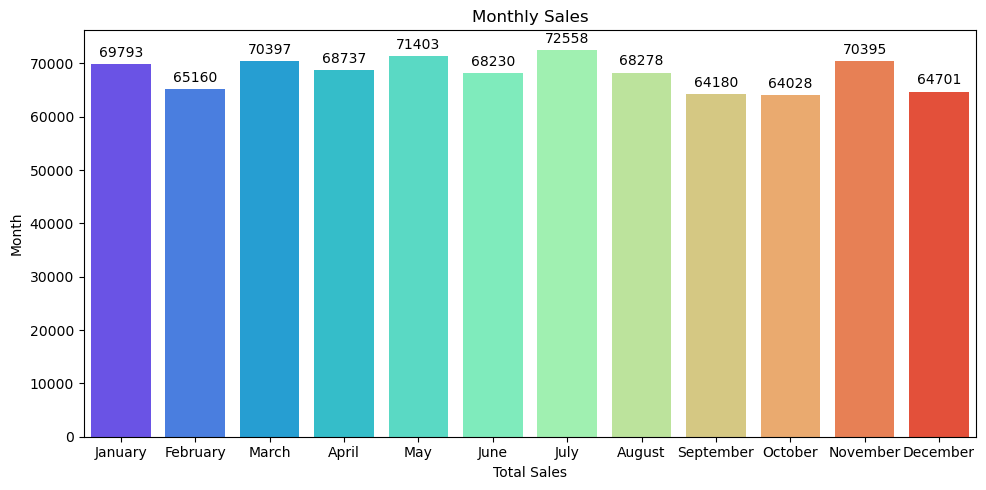

In [22]:
plt.figure(figsize=(10,5))
ax = sns.barplot(x=Monthly_sales.index, y=Monthly_sales.values, palette="rainbow")

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)

plt.title("Monthly Sales")
plt.xlabel("Total Sales")
plt.ylabel("Month")
plt.tight_layout()
plt.show()

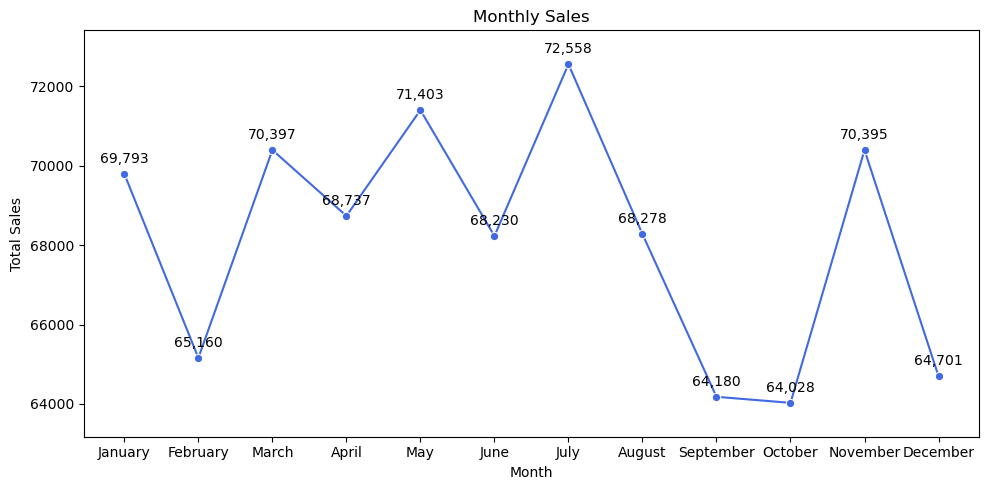

In [23]:
plt.figure(figsize=(10, 5))
ax = sns.lineplot(x=Monthly_sales.index, y=Monthly_sales.values,
                  marker="o", color="royalblue")

# Add data labels above each point
for x, y in zip(Monthly_sales.index, Monthly_sales.values):
    ax.annotate(f"{y:,.0f}", (x, y),
                textcoords="offset points", xytext=(0, 8),
                ha="center")

ax.margins(y=0.1)  

plt.title("Monthly Sales")
plt.xlabel("Month")          
plt.ylabel("Total Sales")  
plt.tight_layout()
plt.show()

In [24]:
# Month Growth 
MoM_Growth = pd.DataFrame({
    "Current_Sales": Monthly_sales,
    "Previous_Sales": Monthly_sales.shift(1)
})

MoM_Growth["MoM_Growth_%"] = round(
    (MoM_Growth["Current_Sales"] - MoM_Growth["Previous_Sales"]) * 100
    / MoM_Growth["Previous_Sales"], 2
)

print("MoM Growth %:")
print(MoM_Growth)

MoM Growth %:
           Current_Sales  Previous_Sales  MoM_Growth_%
Month                                                 
January         69793.30             NaN           NaN
February        65159.60        69793.30         -6.64
March           70397.10        65159.60          8.04
April           68736.80        70397.10         -2.36
May             71402.75        68736.80          3.88
June            68230.20        71402.75         -4.44
July            72557.90        68230.20          6.34
August          68278.25        72557.90         -5.90
September       64180.05        68278.25         -6.00
October         64027.60        64180.05         -0.24
November        70395.35        64027.60          9.95
December        64701.15        70395.35         -8.09


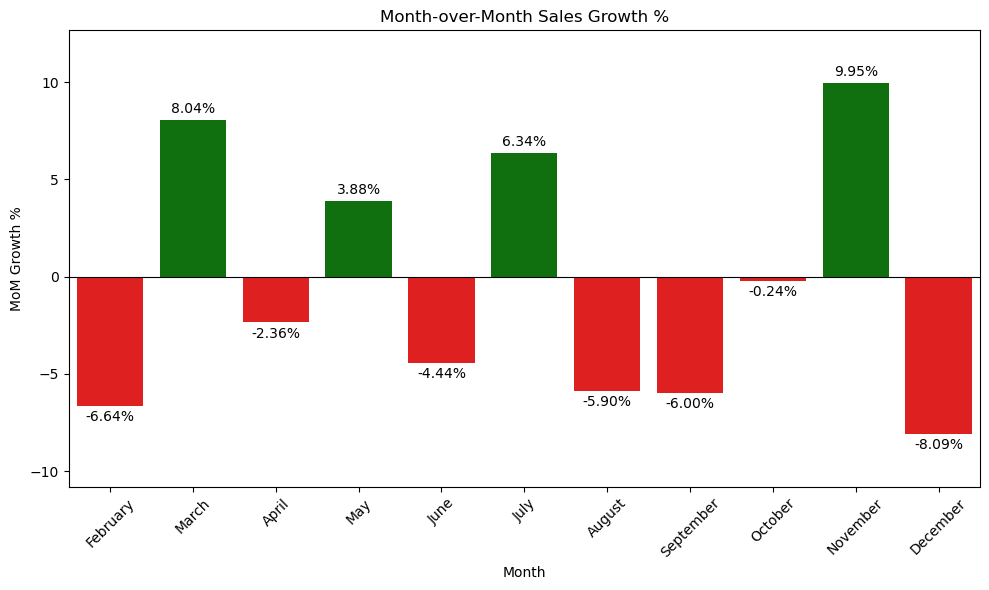

In [25]:
# Drop January (NaN) so it doesn't show as an empty bar
plot_df = MoM_Growth.dropna(subset=["MoM_Growth_%"])

colors = ["green" if v >= 0 else "red" for v in plot_df["MoM_Growth_%"]]

plt.figure(figsize=(10, 6))
ax = sns.barplot(x=plot_df.index, y=plot_df["MoM_Growth_%"],
                 hue=plot_df.index, palette=dict(zip(plot_df.index, colors)), legend=False)

for container in ax.containers:
    ax.bar_label(container, labels=[f"{v:.2f}%" for v in container.datavalues], padding=3)

ax.axhline(0, color="black", linewidth=0.8)  # zero line
plt.title("Month-over-Month Sales Growth %")
plt.xlabel("Month")
plt.ylabel("MoM Growth %")
plt.xticks(rotation=45)
ax.margins(y=0.15)
plt.tight_layout()
plt.show()

In [26]:
Weekly_sales= df.groupby("Weekday")["total_price"].sum()
print(Weekly_sales)

Weekday
Friday       136073.90
Monday       107329.55
Saturday     123182.40
Sunday        99203.50
Thursday     123528.50
Tuesday      114133.80
Wednesday    114408.40
Name: total_price, dtype: float64


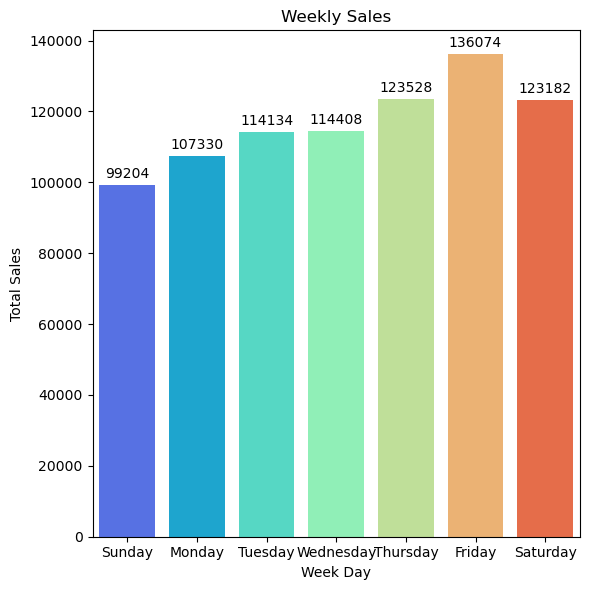

In [27]:
week_order=["Sunday","Monday","Tuesday","Wednesday","Thursday","Friday","Saturday"]
Weekly_sales= df.groupby("Weekday")["total_price"].sum().reindex(week_order)
plt.figure(figsize=(6, 6))
ax = sns.barplot(x=Weekly_sales.index, y=Weekly_sales.values, palette="rainbow")

# Add data labels on top of each bar
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)

plt.title("Weekly Sales")
plt.xlabel("Week Day")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.show()

In [28]:
# Busiest hours (by unique orders)
Hourly_orders = df.groupby("order_Hour")["order_id"].nunique()
print(Hourly_orders.idxmax(), Hourly_orders.max())

12 2520


In [29]:
# Category Wise Sales and Orders 

In [30]:
Cat_sales=df.groupby("pizza_category")["total_price"].sum().sort_values(ascending=False)
Cat_sales

pizza_category
Classic    220053.10
Supreme    208197.00
Chicken    195919.50
Veggie     193690.45
Name: total_price, dtype: float64

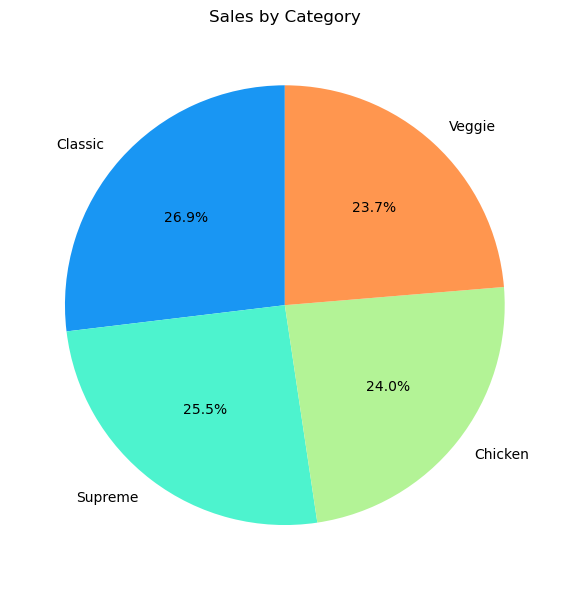

In [31]:
plt.figure(figsize=(6, 6))
plt.pie(Cat_sales.values,
        labels=Cat_sales.index,
        autopct="%1.1f%%",   # percentage on each slice
        startangle=90,
        colors=sns.color_palette("rainbow", len(Cat_sales)))
plt.title("Sales by Category")
plt.tight_layout()
plt.show()

In [32]:
Cat_orders=df.groupby("pizza_category")["order_id"].count().sort_values(ascending=False)
Cat_orders

pizza_category
Classic    14579
Supreme    11777
Veggie     11449
Chicken    10815
Name: order_id, dtype: int64

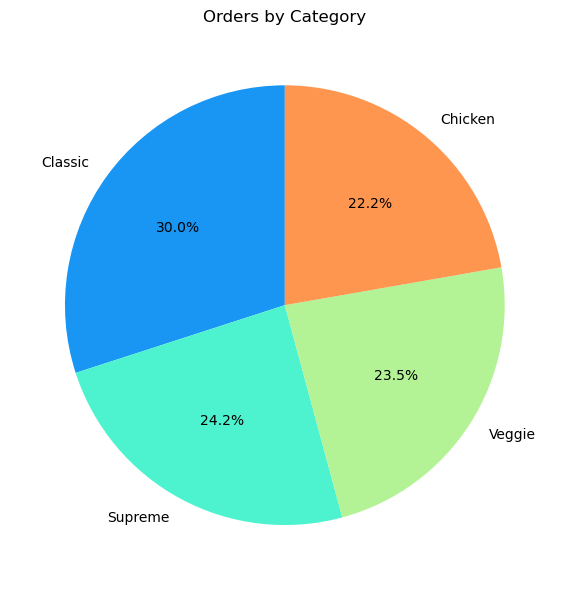

In [33]:
plt.figure(figsize=(6, 6))
plt.pie(Cat_orders.values,
        labels=Cat_orders.index,
        autopct="%1.1f%%",   # percentage on each slice
        startangle=90,
        colors=sns.color_palette("rainbow", len(Cat_sales)))
plt.title("Orders by Category")
plt.tight_layout()
plt.show()

In [34]:
# Pizza Size Wise Sales and Ordders

In [35]:
Pizza_size_sales=df.groupby("pizza_size")["total_price"].sum().sort_values(ascending=False)
Pizza_size_sales

pizza_size
L      375318.70
M      249382.25
S      178076.50
XL      14076.00
XXL      1006.60
Name: total_price, dtype: float64

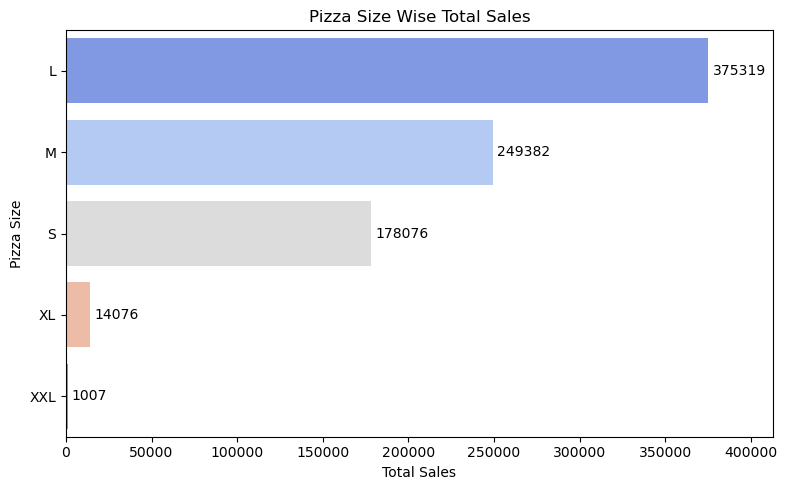

In [36]:
plt.figure(figsize=(8, 5))
ax = sns.barplot(y=Pizza_size_sales.index, x=Pizza_size_sales.values,
                 hue=Pizza_size_sales.index, palette="coolwarm", legend=False)

# Add data labels at the end of each bar
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)

ax.margins(x=0.1)  # extra room on the right so labels don't get clipped

plt.title("Pizza Size Wise Total Sales")
plt.ylabel("Pizza Size")
plt.xlabel("Total Sales")
plt.tight_layout()
plt.show()

In [37]:
Pizza_size_orders=df.groupby("pizza_size")["order_id"].count().sort_values(ascending=False)
Pizza_size_orders

pizza_size
L      18526
M      15385
S      14137
XL       544
XXL       28
Name: order_id, dtype: int64

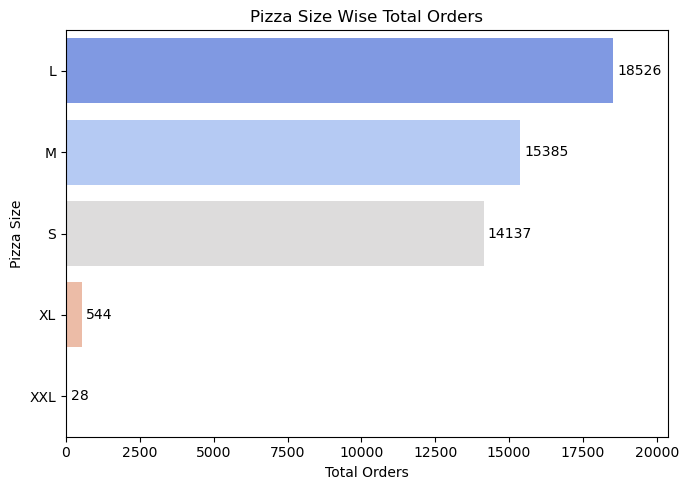

In [38]:
plt.figure(figsize=(7, 5))
ax = sns.barplot(y=Pizza_size_orders.index, x=Pizza_size_orders.values,
                 hue=Pizza_size_orders.index, palette="coolwarm", legend=False)

# Add data labels at the end of each bar
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)

ax.margins(x=0.1)  # extra room on the right so labels don't get clipped

plt.title("Pizza Size Wise Total Orders")
plt.ylabel("Pizza Size")
plt.xlabel("Total Orders")
plt.tight_layout()
plt.show()

In [39]:
# Top 10 Pizza by Sales and orders

In [40]:
Top_10_Pizza_sales=df.groupby("pizza_name")["total_price"].sum().sort_values(ascending=False).head(10)
print(Top_10_Pizza_sales)

pizza_name
The Thai Chicken Pizza          43434.25
The Barbecue Chicken Pizza      42768.00
The California Chicken Pizza    41409.50
The Classic Deluxe Pizza        38180.50
The Spicy Italian Pizza         34831.25
The Southwest Chicken Pizza     34705.75
The Italian Supreme Pizza       33476.75
The Hawaiian Pizza              32273.25
The Four Cheese Pizza           32265.70
The Sicilian Pizza              30940.50
Name: total_price, dtype: float64


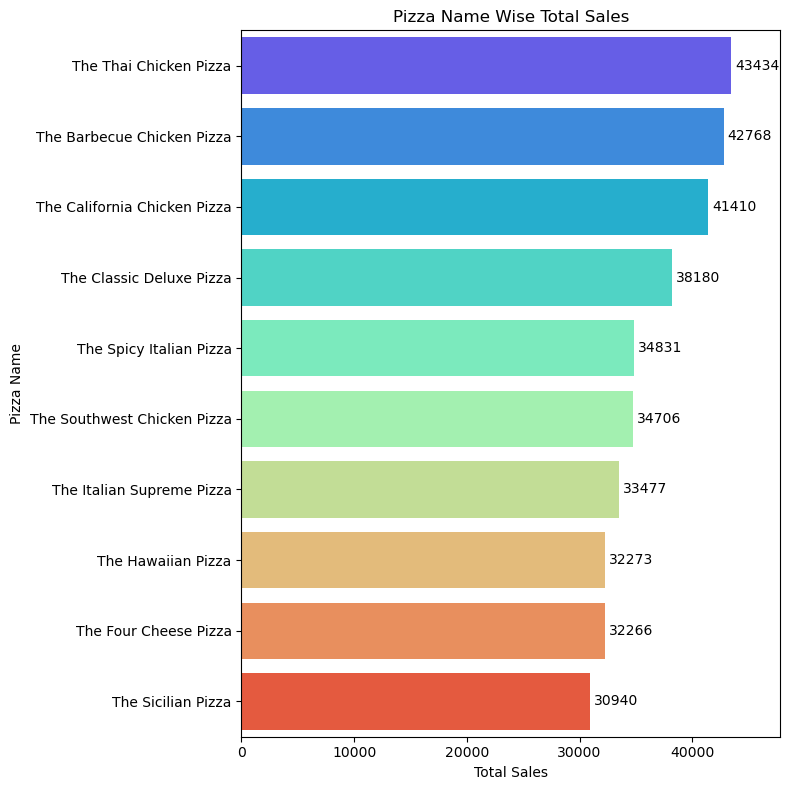

In [41]:
plt.figure(figsize=(8, 8))
ax = sns.barplot(y=Top_10_Pizza_sales.index, x=Top_10_Pizza_sales.values,
                 hue=Top_10_Pizza_sales.index, palette="rainbow", legend=False)

# Add data labels at the end of each bar
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)

ax.margins(x=0.1)  # extra room on the right so labels don't get clipped

plt.title("Pizza Name Wise Total Sales")
plt.ylabel("Pizza Name")
plt.xlabel("Total Sales")
plt.tight_layout()
plt.show()

In [42]:
Bottam_10_Pizza_sales=df.groupby("pizza_name")["total_price"].sum().sort_values(ascending=False).tail(10)
print(Bottam_10_Pizza_sales)

pizza_name
The Chicken Alfredo Pizza       16900.25
The Chicken Pesto Pizza         16701.75
The Soppressata Pizza           16425.75
The Italian Vegetables Pizza    16019.25
The Calabrese Pizza             15934.25
The Spinach Pesto Pizza         15596.00
The Mediterranean Pizza         15360.50
The Spinach Supreme Pizza       15277.75
The Green Garden Pizza          13955.75
The Brie Carre Pizza            11588.50
Name: total_price, dtype: float64


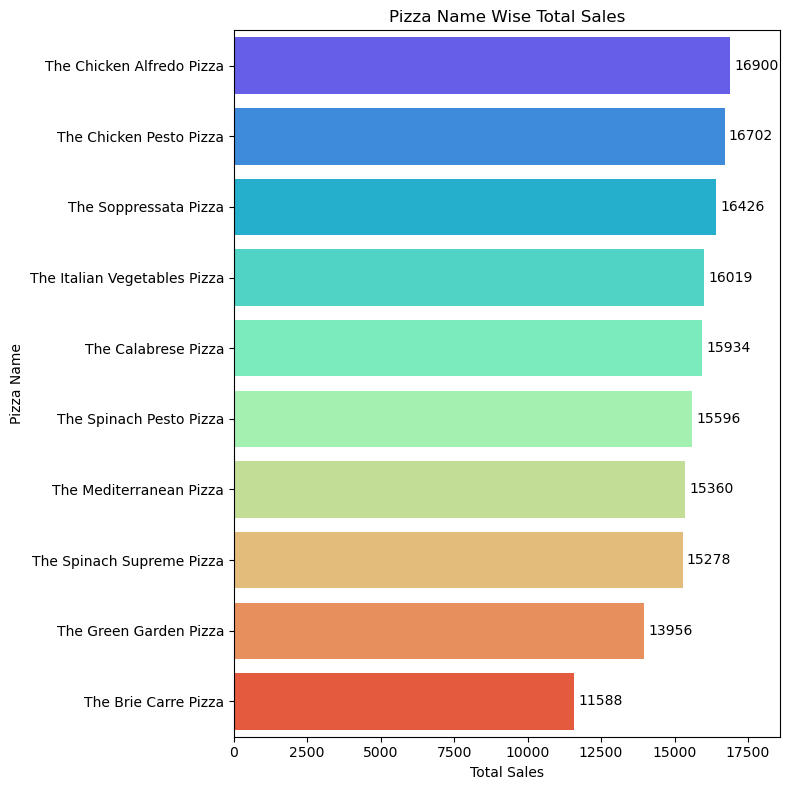

In [43]:
plt.figure(figsize=(8, 8))
ax = sns.barplot(y=Bottam_10_Pizza_sales.index, x=Bottam_10_Pizza_sales.values,
                 hue=Bottam_10_Pizza_sales.index, palette="rainbow", legend=False)

# Add data labels at the end of each bar
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)

ax.margins(x=0.1)  # extra room on the right so labels don't get clipped

plt.title("Pizza Name Wise Total Sales")
plt.ylabel("Pizza Name")
plt.xlabel("Total Sales")
plt.tight_layout()
plt.show()

In [44]:
Top_10_Pizza_orders=df.groupby("pizza_name")["order_id"].count().sort_values(ascending=False).head(10)
print(Top_10_Pizza_orders)

pizza_name
The Classic Deluxe Pizza        2416
The Barbecue Chicken Pizza      2372
The Hawaiian Pizza              2370
The Pepperoni Pizza             2369
The Thai Chicken Pizza          2315
The California Chicken Pizza    2302
The Spicy Italian Pizza         1887
The Sicilian Pizza              1887
The Southwest Chicken Pizza     1885
The Four Cheese Pizza           1850
Name: order_id, dtype: int64


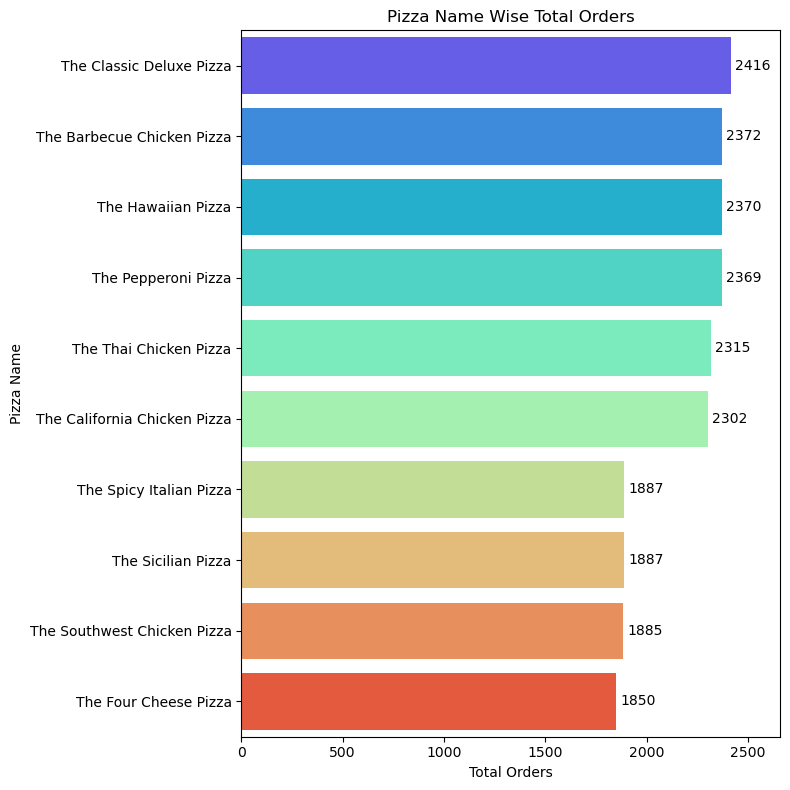

In [45]:
plt.figure(figsize=(8, 8))
ax = sns.barplot(y=Top_10_Pizza_orders.index, x=Top_10_Pizza_orders.values,
                 hue=Top_10_Pizza_orders.index, palette="rainbow", legend=False)

# Add data labels at the end of each bar
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)

ax.margins(x=0.1)  # extra room on the right so labels don't get clipped

plt.title("Pizza Name Wise Total Orders")
plt.ylabel("Pizza Name")
plt.xlabel("Total Orders")
plt.tight_layout()
plt.show()

In [46]:
# top 5 Sales by pizza_ingredients

In [47]:
Sales_ing=df.groupby("pizza_ingredients")["total_price"].sum().sort_values(ascending=False).head(10)
Sales_ing

pizza_ingredients
Chicken, Pineapple, Tomatoes, Red Peppers, Thai Sweet Chilli Sauce                                   43434.25
Barbecued Chicken, Red Peppers, Green Peppers, Tomatoes, Red Onions, Barbecue Sauce                  42768.00
Chicken, Artichoke, Spinach, Garlic, Jalapeno Peppers, Fontina Cheese, Gouda Cheese                  41409.50
Pepperoni, Mushrooms, Red Onions, Red Peppers, Bacon                                                 38180.50
Capocollo, Tomatoes, Goat Cheese, Artichokes, Peperoncini verdi, Garlic                              34831.25
Chicken, Tomatoes, Red Peppers, Red Onions, Jalapeno Peppers, Corn, Cilantro, Chipotle Sauce         34705.75
Calabrese Salami, Capocollo, Tomatoes, Red Onions, Green Olives, Garlic                              33476.75
Sliced Ham, Pineapple, Mozzarella Cheese                                                             32273.25
Ricotta Cheese, Gorgonzola Piccante Cheese, Mozzarella Cheese, Parmigiano Reggiano Cheese, Garlic    3

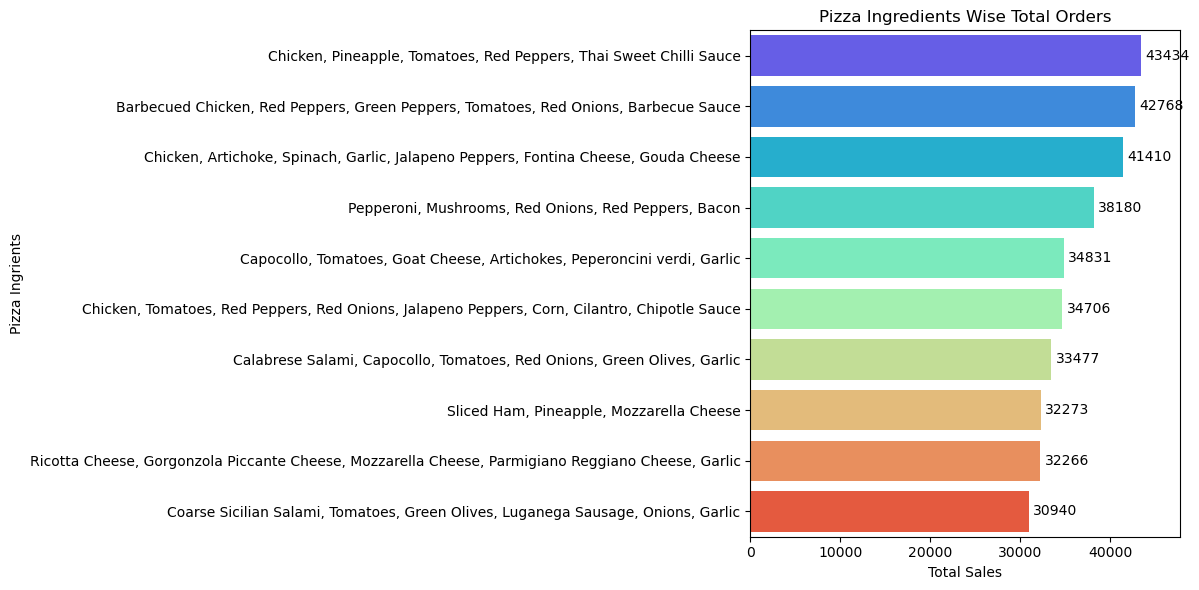

In [48]:
plt.figure(figsize=(12, 6))
ax = sns.barplot(y=Sales_ing.index, x=Sales_ing.values,
                 hue=Sales_ing.index, palette="rainbow", legend=False)

# Add data labels at the end of each bar
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)

ax.margins(x=0.1)  # extra room on the right so labels don't get clipped

plt.title("Pizza Ingredients Wise Total Orders")
plt.ylabel("Pizza Ingrients")
plt.xlabel("Total Sales")
plt.tight_layout()
plt.show()

In [49]:
# Most common ingredients 
ingredients = (df["pizza_ingredients"].str.split(", ")
                 .explode().value_counts().head(10))
ingredients

pizza_ingredients
Garlic               27422
Tomatoes             26601
Red Onions           19547
Red Peppers          16284
Mozzarella Cheese    10333
Pepperoni            10300
Spinach              10012
Mushrooms             9624
Chicken               8443
Capocollo             6572
Name: count, dtype: int64

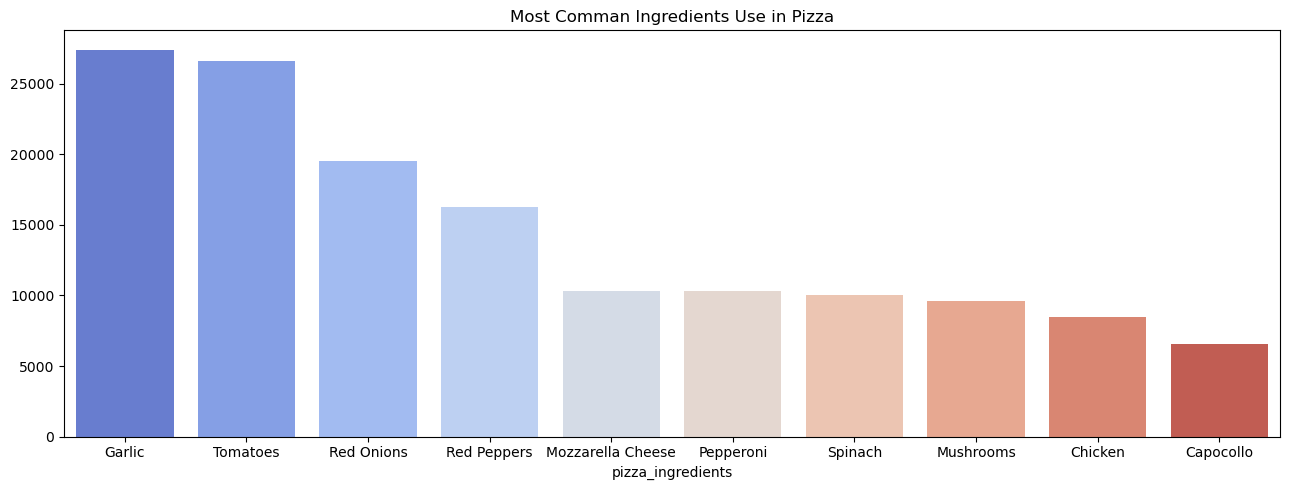

In [50]:
plt.figure(figsize=(13,5))
sns.barplot(x=ingredients.index,y=ingredients.values,palette="coolwarm")
plt.title("Most Comman Ingredients Use in Pizza")
plt.tight_layout()
plt.show()

#### Order behavior

In [51]:
# Distribution of order sizes (pizzas per order)
order_qty = df.groupby("order_id")["quantity"].sum()
order_qty.describe()
order_qty.value_counts().sort_index()


quantity
1     8111
2     6152
3     3207
4     3122
5      145
6       80
7       61
8       67
9       64
10      56
11      56
12      54
13      50
14      66
15      57
25       1
28       1
Name: count, dtype: int64

<Axes: xlabel='total_price', ylabel='Count'>

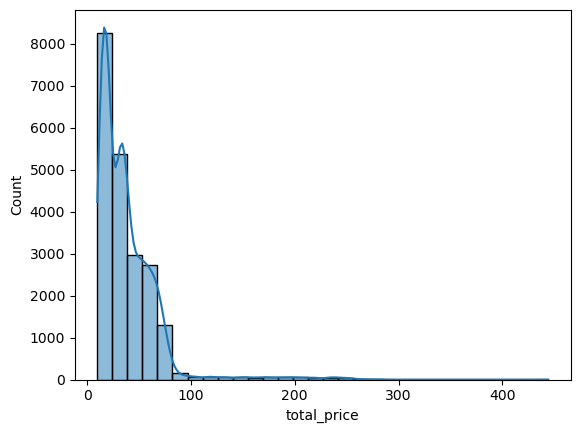

In [52]:
# Order value distribution
order_value = df.groupby("order_id")["total_price"].sum()
order_value.describe()
sns.histplot(order_value, bins=30, kde=True)

In [53]:
Pizza_size_cat_Sales=df.pivot_table(values="total_price", index="pizza_category",
               columns="pizza_size", aggfunc="sum")
Pizza_size_cat_Sales

pizza_size,L,M,S,XL,XXL
pizza_category,,,,,
Chicken,102339.0,65224.50,28356.00,NaN,NaN
Classic,74518.5,60581.75,69870.25,14076.0,1006.6
Supreme,94258.5,66475.00,47463.50,NaN,NaN
Veggie,104202.7,57101.00,32386.75,NaN,NaN


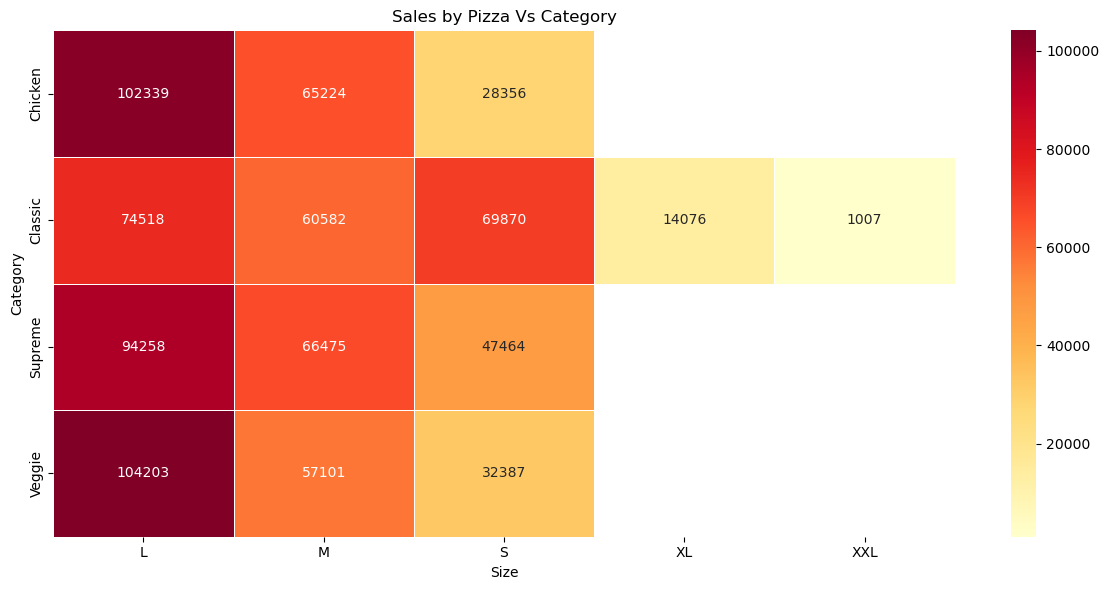

In [54]:
plt.figure(figsize=(12, 6))
sns.heatmap(Pizza_size_cat_Sales, annot=True, fmt=".0f", cmap="YlOrRd", linewidths=0.5)
plt.title("Sales by Pizza Vs Category")
plt.xlabel("Size")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

In [55]:
# Pivot Table Total order with day vs hours 

In [56]:
pivot_table = df.pivot_table(values="order_id",
                             index="Weekday",
                             columns="order_Hour",
                             aggfunc="count")
days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
pivot_table = pivot_table.reindex(days)
pivot_table

order_Hour,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
Weekday,,,,,,,,,,,,,,,
Monday,NaN,3.0,461.0,1101.0,774.0,450.0,407.0,534.0,708.0,654.0,529.0,357.0,277.0,110.0,4.0
Tuesday,4.0,NaN,419.0,1068.0,988.0,471.0,417.0,618.0,663.0,632.0,590.0,470.0,268.0,145.0,NaN
Wednesday,NaN,4.0,522.0,1021.0,907.0,501.0,457.0,563.0,757.0,750.0,512.0,389.0,269.0,145.0,NaN
Thursday,NaN,5.0,459.0,1106.0,1095.0,563.0,460.0,642.0,840.0,796.0,580.0,447.0,216.0,111.0,3.0
Friday,NaN,NaN,379.0,1064.0,1020.0,513.0,432.0,572.0,752.0,926.0,736.0,695.0,613.0,378.0,26.0
Saturday,NaN,3.0,205.0,603.0,766.0,513.0,516.0,641.0,721.0,873.0,834.0,726.0,584.0,339.0,31.0
Sunday,NaN,2.0,227.0,580.0,653.0,510.0,481.0,615.0,702.0,728.0,569.0,403.0,301.0,142.0,4.0


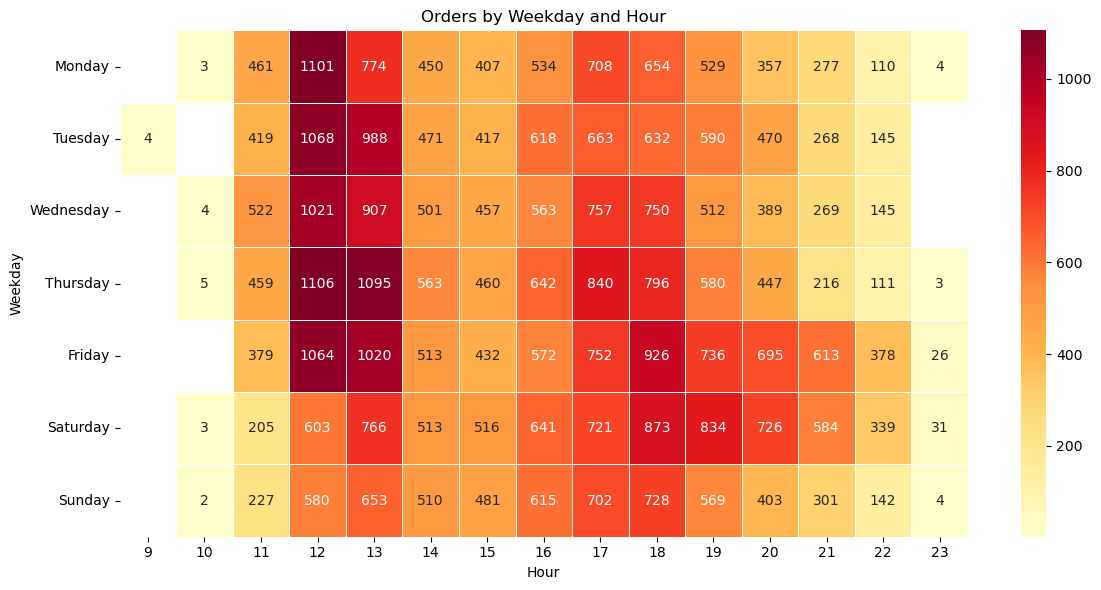

In [57]:
plt.figure(figsize=(12, 6))
sns.heatmap(pivot_table, annot=True, fmt=".0f", cmap="YlOrRd", linewidths=0.5)
plt.title("Orders by Weekday and Hour")
plt.xlabel("Hour")
plt.ylabel("Weekday")
plt.tight_layout()
plt.show()

####  Statistical tests

In [58]:
# Correlation between quantity and total price
corr=df[["quantity", "unit_price", "total_price"]].corr()
corr

,quantity,unit_price,total_price
quantity,1.000000,0.007142,0.541926
unit_price,0.007142,1.000000,0.836087
total_price,0.541926,0.836087,1.000000


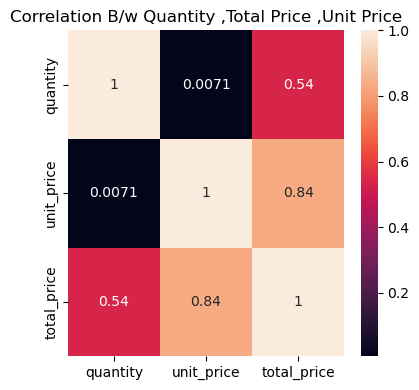

In [59]:
plt.figure(figsize=(4, 4))
sns.heatmap(corr, annot=True)
plt.title("Correlation B/w Quantity ,Total Price ,Unit Price")
plt.tight_layout()
plt.show()

In [60]:
# Are weekend orders bigger than weekday orders?

In [61]:
import numpy as np
from scipy import stats

# 1. One row per order, with its total value and weekday
order_df = df.groupby("order_id").agg(
    order_value=("total_price", "sum"),
    Weekday=("Weekday", "first")
).reset_index()

# 2. Split into weekend and weekday orders
is_weekend = order_df["Weekday"].isin(["Saturday", "Sunday"])
weekend = order_df[is_weekend]["order_value"]
weekday = order_df[~is_weekend]["order_value"]

# 3. Compare the averages
print("Weekend average:", round(weekend.mean(), 2))
print("Weekday average:", round(weekday.mean(), 2))

# 4. Statistical test (is weekend bigger?)
t_stat, p_value = stats.ttest_ind(weekend, weekday, equal_var=False, alternative="greater")
print("p-value:", round(p_value, 4))

# 5. Conclusion
if p_value < 0.05:
    print("Weekend orders are significantly bigger.")
else:
    print("No significant proof that weekend orders are bigger.")

Weekend average: 38.46
Weekday average: 38.25
p-value: 0.3251
No significant proof that weekend orders are bigger.


In [62]:
# Is pizza category related to size? (chi-square)

In [63]:
import pandas as pd
from scipy import stats

# 1. Count how many rows fall in each category + size combination
ct = pd.crosstab(df["pizza_category"], df["pizza_size"])
print(ct, "\n")

# 2. Run the chi-square test
chi2, p_value, dof, expected = stats.chi2_contingency(ct)

print("Chi-square value:", round(chi2, 2))
print("p-value:", round(p_value, 4))
print("Degrees of freedom:", dof)

# 3. Conclusion
if p_value < 0.05:
    print("Category and size are related.")
else:
    print("No significant relationship between category and size.")

pizza_size         L     M     S   XL  XXL
pizza_category                            
Chicken         4799  3811  2205    0    0
Classic         3987  4045  5975  544   28
Supreme         4477  3977  3323    0    0
Veggie          5263  3552  2634    0    0 

Chi-square value: 3347.83
p-value: 0.0
Degrees of freedom: 12
Category and size are related.


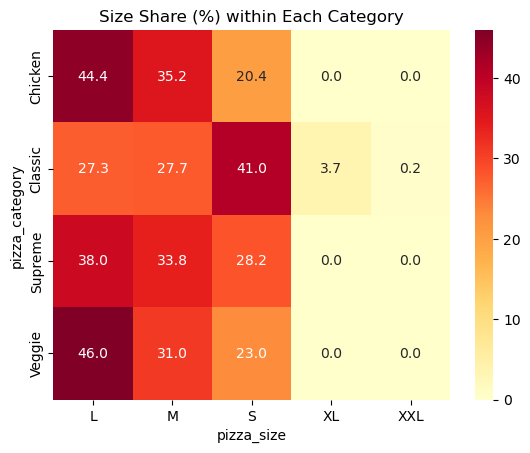

In [64]:
# Percentage of each category's sales by size
ct_pct = pd.crosstab(df["pizza_category"], df["pizza_size"], normalize="index") * 100

sns.heatmap(ct_pct, annot=True, fmt=".1f", cmap="YlOrRd")
plt.title("Size Share (%) within Each Category")
plt.show()